# Starter Code — Stereo Vision dengan 1 HP

**Petunjuk persiapan foto, alat, dan hal yang harus dicatat ada di `README.md`.** Notebook ini untuk menjalankan kode dan mengisi hasil. Jalankan **A → G** berurutan.

## A — Konfigurasi dan pemeriksaan file
Isi tiga nilai yang diukur. Untuk Colab, ubah `UPLOAD_ZIP = True`.

In [60]:
from pathlib import Path
import os, zipfile, csv, hashlib
import cv2
import numpy as np
import matplotlib.pyplot as plt

PATTERN_SIZE = (9, 6)        # sudut dalam; papan cetak 10 x 7 kotak
SQUARE_SIZE_MM = 25.0        # GANTI dengan ukuran satu kotak hasil penggaris
BASELINE_CM = 20.0           # Terukur: pusat lensa kiri 0 cm, kanan 20 cm
UPLOAD_ZIP = False          # True hanya di Google Colab
DATA_DIR = Path('.') if not UPLOAD_ZIP else Path('/content/PROJEK_COMVIS')

CAL_DIR = DATA_DIR/'calibration'
STEREO_DIR = DATA_DIR/'stereo'
OUT = DATA_DIR/'output'
OUT.mkdir(parents=True, exist_ok=True)
image_ext = {'.jpg','.jpeg','.png','.bmp'}
cal_files = sorted(p for p in CAL_DIR.iterdir() if p.suffix.lower() in image_ext) if CAL_DIR.exists() else []
L_PATH, R_PATH = STEREO_DIR/'kiri 50.jpeg', STEREO_DIR/'kanan 50.jpeg'
print('OpenCV:',cv2.__version__)
print('Foto kalibrasi:',len(cal_files),'| kiri:',L_PATH.exists(),'| kanan:',R_PATH.exists())
print('Kotak:',SQUARE_SIZE_MM,'mm | baseline:',BASELINE_CM,'cm')
if SQUARE_SIZE_MM <= 0 or BASELINE_CM <= 0: raise ValueError('Ukuran kotak dan baseline harus positif.')
if len(cal_files) < 10: raise RuntimeError('Sediakan setidaknya 10 foto kalibrasi (disarankan 15–25).')
if not L_PATH.exists() or not R_PATH.exists(): raise FileNotFoundError('Periksa stereo/kiri 100.jpeg dan stereo/kanan 100.jpeg')

OpenCV: 5.1.0
Foto kalibrasi: 21 | kiri: True | kanan: True
Kotak: 25.0 mm | baseline: 20.0 cm


## B — Deteksi sudut chessboard dan ukur jarak dalam piksel
Hasil `contoh jarak 2 sudut` adalah nilai **foto**, bukan focal length. Foto gagal otomatis dilewati.

Foto valid: 16 | Gagal: 5
Foto gagal: ['cal 13.jpeg', 'cal 16.jpeg', 'cal 2.jpeg', 'cal 3.jpeg', 'cal 4.jpeg']
Contoh jarak dua sudut dalam piksel: 84.12


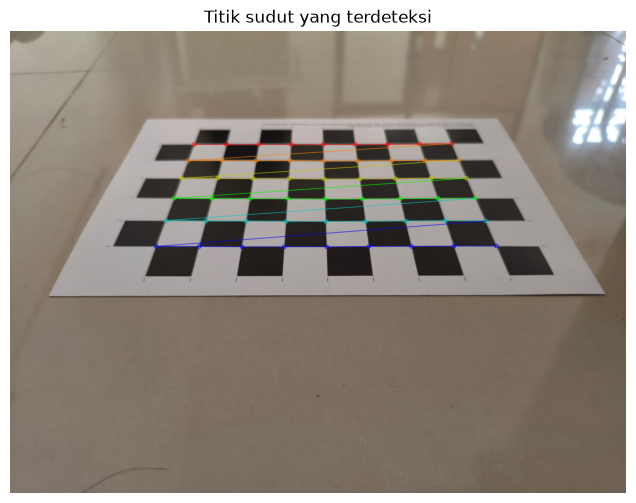

In [61]:
cols, rows = PATTERN_SIZE
obj = np.zeros((cols*rows,3),np.float32)
obj[:,:2] = np.mgrid[0:cols,0:rows].T.reshape(-1,2) * SQUARE_SIZE_MM
objpoints, imgpoints, ok_files, bad_files, spacings = [],[],[],[],[]
size_wh = None
preview = None
for path in cal_files:
    img = cv2.imread(str(path))
    if img is None: bad_files.append(path.name); continue
    gray = cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
    wh = (gray.shape[1],gray.shape[0])
    if size_wh is None: size_wh=wh
    if wh != size_wh:
        bad_files.append(path.name+' (resolusi berbeda)'); continue
    found,corners = cv2.findChessboardCornersSB(gray, PATTERN_SIZE)
    if not found: bad_files.append(path.name); continue
    corners = corners.astype(np.float32)
    objpoints.append(obj.copy()); imgpoints.append(corners)
    ok_files.append(path.name)
    spacings.append(float(np.linalg.norm(corners[1,0]-corners[0,0])))
    if preview is None:
        preview=img.copy()
        cv2.drawChessboardCorners(preview,PATTERN_SIZE,corners,True)
print('Foto valid:',len(ok_files),'| Gagal:',len(bad_files))
print('Foto gagal:',bad_files)
print('Contoh jarak dua sudut dalam piksel:', round(spacings[0],2) if spacings else None)
if preview is not None:
    plt.figure(figsize=(10,6));plt.imshow(cv2.cvtColor(preview,cv2.COLOR_BGR2RGB));plt.title('Titik sudut yang terdeteksi');plt.axis('off');plt.show()
    cv2.imwrite(str(OUT/'corners_preview.jpg'),preview)
if len(ok_files) < 10: raise RuntimeError('Titik sudut berhasil dideteksi pada <10 foto. Ulangi/ambil foto baru.')

## C — Kalibrasi kamera: hasil `fx`, `fy`, `cx`, `cy`
Periksa RMS dan simpan hasilnya. **Tidak ada angka focal length asumsi**.

In [62]:
rms,K,dist,rvecs,tvecs=cv2.calibrateCamera(objpoints,imgpoints,size_wh,None,None)
fx,fy,cx,cy = K[0,0],K[1,1],K[0,2],K[1,2]
print('Resolusi kalibrasi:',size_wh)
print('K =\n',K)
print(f'fx={fx:.2f} px | fy={fy:.2f} px | cx={cx:.2f} px | cy={cy:.2f} px')
print(f'RMS reprojection error={rms:.3f} px')
print('Distorsi:',dist.ravel())
np.savez(OUT/'calibration.npz',K=K,dist=dist,image_wh=size_wh,rms=rms,square_size_mm=SQUARE_SIZE_MM)
if not np.isfinite(rms) or rms > 2.0:
    print('PERHATIAN: RMS cukup besar. Periksa foto kalibrasi dan kesesuaian pola.')

Resolusi kalibrasi: (1600, 1200)
K =
 [[1.25908570e+03 0.00000000e+00 7.95960981e+02]
 [0.00000000e+00 1.25630623e+03 5.99457531e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
fx=1259.09 px | fy=1256.31 px | cx=795.96 px | cy=599.46 px
RMS reprojection error=0.531 px
Distorsi: [ 1.26570928e-01 -4.42464976e-01 -2.78403051e-03 -3.93386393e-04
  1.91510631e-01]


## D ? Cek alignment pasangan foto
Matching fitur dilakukan pada seluruh gambar tanpa pemotongan atau ROI. Sel ini memeriksa alignment untuk uji 1 (1,00 m), uji 2 (0,50 m), dan uji 3 (1,50 m).


uji_01: match global=379 | inlier=201 | median beda baris setelah rectification=0.63 px | T_x/|T|=-0.258 | error epipolar=0.39 px | alignment=OK
PERINGATAN: kiri 50.jpeg identik dengan kanan 100.jpeg.
uji_2: match global=419 | inlier=187 | median beda baris setelah rectification=0.53 px | T_x/|T|=0.998 | error epipolar=0.37 px | alignment=OK
uji_3: match global=523 | inlier=354 | median beda baris setelah rectification=0.46 px | T_x/|T|=-0.999 | error epipolar=0.33 px | alignment=OK


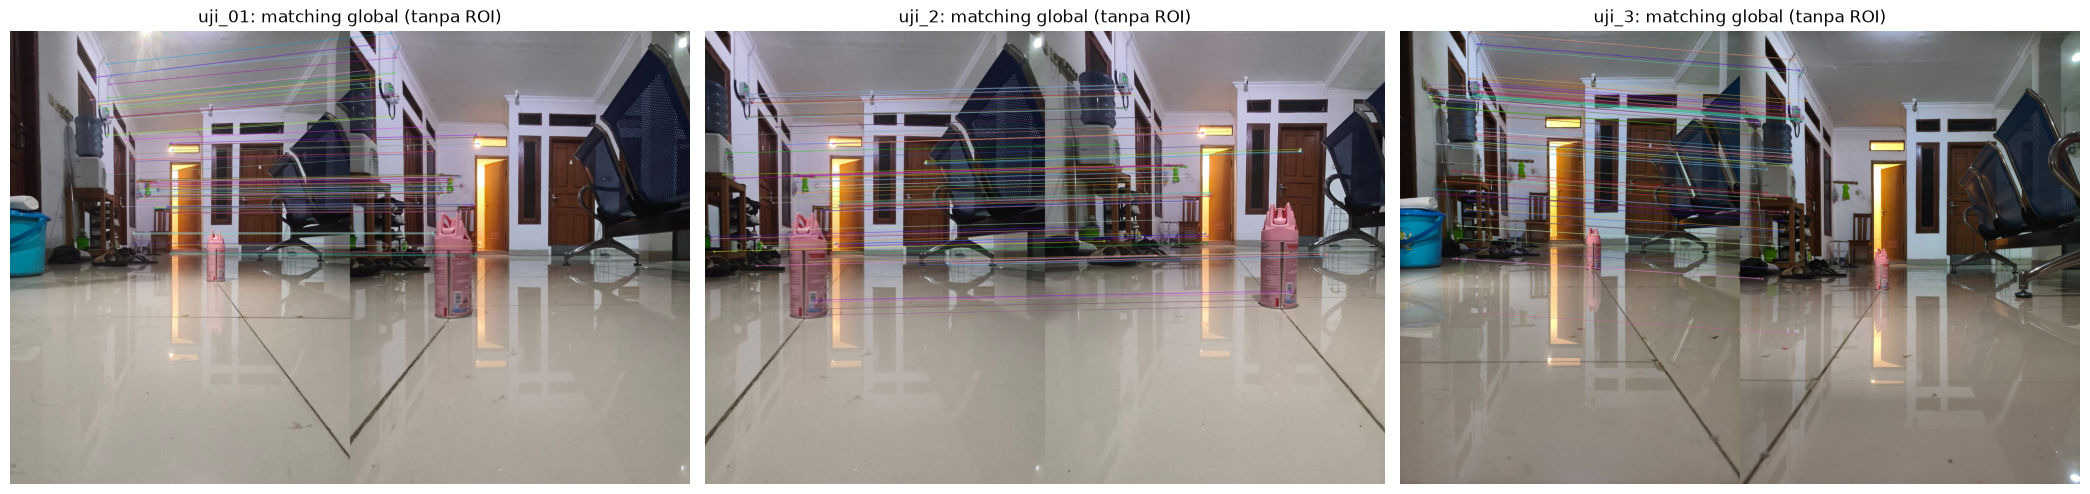

In [63]:
ALIGNMENT_TRIALS={'uji_01':100,'uji_2':50,'uji_3':150}
ALIGNMENT_RESULTS={}
match_panels=[]
seen_images={}
for test_id,distance_cm in ALIGNMENT_TRIALS.items():
    left_path=STEREO_DIR/f'kiri {distance_cm}.jpeg'
    right_path=STEREO_DIR/f'kanan {distance_cm}.jpeg'
    if not left_path.exists() or not right_path.exists():
        ALIGNMENT_RESULTS[test_id]={'ok':False,'reason':'foto kiri/kanan tidak ditemukan'}
        print(f'{test_id}: foto kiri/kanan tidak ditemukan.')
        continue
    for image_path in (left_path,right_path):
        digest=hashlib.sha256(image_path.read_bytes()).hexdigest()
        if digest in seen_images:
            print(f'PERINGATAN: {image_path.name} identik dengan {seen_images[digest]}.')
        else:
            seen_images[digest]=image_path.name
    left=cv2.imread(str(left_path));right=cv2.imread(str(right_path))
    if left is None or right is None or left.shape!=right.shape:
        ALIGNMENT_RESULTS[test_id]={'ok':False,'reason':'foto gagal dibaca atau resolusi berbeda'}
        print(f'{test_id}: foto gagal dibaca atau resolusi berbeda.')
        continue
    gray_left=cv2.cvtColor(left,cv2.COLOR_BGR2GRAY)
    gray_right=cv2.cvtColor(right,cv2.COLOR_BGR2GRAY)
    sift=cv2.SIFT_create(nfeatures=8000,contrastThreshold=0.015)
    kp_left,desc_left=sift.detectAndCompute(gray_left,None)
    kp_right,desc_right=sift.detectAndCompute(gray_right,None)
    if desc_left is None or desc_right is None:
        ALIGNMENT_RESULTS[test_id]={'ok':False,'reason':'fitur global tidak cukup'}
        print(f'{test_id}: fitur global tidak cukup.')
        continue
    pairs=cv2.BFMatcher().knnMatch(desc_left,desc_right,k=2)
    good=[m for m,n in pairs if m.distance<0.75*n.distance]
    if len(good)<30:
        ALIGNMENT_RESULTS[test_id]={'ok':False,'reason':f'match global hanya {len(good)}'}
        print(f'{test_id}: match global hanya {len(good)}.')
        continue
    points_left=np.float32([kp_left[m.queryIdx].pt for m in good])
    points_right=np.float32([kp_right[m.trainIdx].pt for m in good])
    cv2.setRNGSeed(0)
    F,mask=cv2.findFundamentalMat(points_left,points_right,cv2.FM_RANSAC,1.5,0.99)
    if F is None or mask is None:
        ALIGNMENT_RESULTS[test_id]={'ok':False,'reason':'estimasi fundamental matrix gagal'}
        print(f'{test_id}: estimasi fundamental matrix gagal.')
        continue
    inliers=mask.ravel().astype(bool)
    if int(inliers.sum())<15:
        ALIGNMENT_RESULTS[test_id]={'ok':False,'reason':f'inlier global hanya {int(inliers.sum())}'}
        print(f'{test_id}: inlier global hanya {int(inliers.sum())}.')
        continue
    rect_ok,H_left,H_right=cv2.stereoRectifyUncalibrated(
        points_left[inliers],points_right[inliers],F,(left.shape[1],left.shape[0]),threshold=5)
    if not rect_ok:
        ALIGNMENT_RESULTS[test_id]={'ok':False,'reason':'rectification alignment gagal'}
        print(f'{test_id}: rectification alignment gagal.')
        continue
    rect_points_left=cv2.perspectiveTransform(points_left[inliers][None,:,:],H_left)[0]
    rect_points_right=cv2.perspectiveTransform(points_right[inliers][None,:,:],H_right)[0]
    median_dy=float(np.median(np.abs(rect_points_left[:,1]-rect_points_right[:,1])))
    calibration=np.load(OUT/'calibration.npz')
    K_cal=calibration['K'].astype(np.float64)
    dist_cal=calibration['dist'].reshape(-1).astype(np.float64)
    calibration_wh=tuple(int(v) for v in calibration['image_wh'])
    image_wh=(left.shape[1],left.shape[0])
    if image_wh==calibration_wh:
        K_trial,dist_trial=K_cal,dist_cal
    elif image_wh==(calibration_wh[1],calibration_wh[0]):
        calibration_width=calibration_wh[0]
        K_trial=np.array([
            [K_cal[1,1],0,K_cal[1,2]],
            [0,K_cal[0,0],calibration_width-1-K_cal[0,2]],
            [0,0,1]],dtype=np.float64)
        dist_trial=np.array([
            dist_cal[0],dist_cal[1],dist_cal[3],-dist_cal[2],dist_cal[4]])
    else:
        ALIGNMENT_RESULTS[test_id]={'ok':False,'reason':'resolusi tidak cocok dengan kalibrasi'}
        print(f'{test_id}: resolusi tidak cocok dengan kalibrasi.')
        continue
    undistorted_left=cv2.undistortPoints(
        points_left.reshape(-1,1,2),K_trial,dist_trial,P=K_trial).reshape(-1,2)
    undistorted_right=cv2.undistortPoints(
        points_right.reshape(-1,1,2),K_trial,dist_trial,P=K_trial).reshape(-1,2)
    E,essential_mask=cv2.findEssentialMat(
        undistorted_left,undistorted_right,K_trial,method=cv2.USAC_MAGSAC,
        prob=0.999,threshold=1.0,maxIters=10000)
    translation_x_fraction=None
    if E is not None and essential_mask is not None:
        pose_count,_,translation,_=cv2.recoverPose(
            E,undistorted_left,undistorted_right,K_trial,mask=essential_mask)
        if pose_count>=40:
            translation_x_fraction=float(translation[0,0]/np.linalg.norm(translation))
    x_left=np.column_stack((points_left[inliers],np.ones(int(inliers.sum()))))
    x_right=np.column_stack((points_right[inliers],np.ones(int(inliers.sum()))))
    Fx_left=(F@x_left.T).T
    Ft_x_right=(F.T@x_right.T).T
    numerator=np.sum(x_right*Fx_left,axis=1)**2
    denominator=Fx_left[:,0]**2+Fx_left[:,1]**2+Ft_x_right[:,0]**2+Ft_x_right[:,1]**2
    median_epipolar=float(np.median(np.sqrt(numerator/np.maximum(denominator,1e-12))))
    ok=median_dy<=2.0 and median_epipolar<=2.0
    ALIGNMENT_RESULTS[test_id]={
        'ok':ok,'median_vertical_error_px':median_dy,
        'translation_x_fraction':translation_x_fraction,
        'median_epipolar_error_px':median_epipolar,
        'matches':len(good),'inliers':int(inliers.sum())}
    matches=[m for m,keep in zip(good,inliers) if keep]
    match_image=cv2.drawMatches(left,kp_left,right,kp_right,matches[:80],None,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    if not cv2.imwrite(str(OUT/f'matches_{test_id}.jpg'),match_image):
        raise OSError(f'Gagal menyimpan matching global {test_id}.')
    match_panels.append((test_id,match_image))
    print(
        f"{test_id}: match global={len(good)} | inlier={int(inliers.sum())} | "
        f"median beda baris setelah rectification={median_dy:.2f} px | "
        f"T_x/|T|={translation_x_fraction if translation_x_fraction is not None else float('nan'):.3f} | "
        f"error epipolar={median_epipolar:.2f} px | alignment={'OK' if ok else 'PERIKSA'}")
if match_panels:
    fig,axes=plt.subplots(1,len(match_panels),figsize=(7*len(match_panels),6))
    if len(match_panels)==1:axes=[axes]
    for axis,(test_id,image) in zip(axes,match_panels):
        axis.imshow(cv2.cvtColor(image,cv2.COLOR_BGR2RGB))
        axis.set_title(f'{test_id}: matching global (tanpa ROI)')
        axis.axis('off')
    plt.tight_layout();plt.show()
ALIGNMENT_OK=bool(ALIGNMENT_RESULTS) and all(
    item.get('ok',False) for item in ALIGNMENT_RESULTS.values())


## E — Siapkan perhitungan disparity
Fungsi di sel ini memproses setiap pasangan foto secara independen, mengestimasi rectification dari fitur global, dan menghitung disparity hanya pada ROI yang diberikan sel F. Koordinat ROI merujuk ke gambar kiri hasil undistort dan rectification.


In [67]:
def portrait_camera_model(calibration, image_shape):
    K_cal=calibration['K'].astype(np.float64)
    dist_cal=calibration['dist'].reshape(-1).astype(np.float64)
    calibration_wh=tuple(int(v) for v in calibration['image_wh'])
    image_wh=(image_shape[1],image_shape[0])
    if image_wh==calibration_wh:
        return K_cal,dist_cal
    if image_wh!=(calibration_wh[1],calibration_wh[0]):
        raise ValueError(f'Resolusi foto {image_wh} tidak cocok dengan kalibrasi {calibration_wh}.')
    width,height=calibration_wh
    K_portrait=np.array([
        [K_cal[1,1],0,K_cal[1,2]],
        [0,K_cal[0,0],width-1-K_cal[0,2]],
        [0,0,1]],dtype=np.float64)
    d=dist_cal
    dist_portrait=np.array([d[0],d[1],d[3],-d[2],d[4]],dtype=np.float64)
    return K_portrait,dist_portrait


def run_stereo_trial(test_id, distance_cm, roi_center_xy, roi_radius=12):
    if test_id not in ALIGNMENT_RESULTS or not ALIGNMENT_RESULTS[test_id].get('ok',False):
        raise RuntimeError(f'Alignment global {test_id} belum lolos pemeriksaan sel D.')
    left_path=STEREO_DIR/f'kiri {distance_cm}.jpeg'
    right_path=STEREO_DIR/f'kanan {distance_cm}.jpeg'
    left=cv2.imread(str(left_path));right=cv2.imread(str(right_path))
    if left is None or right is None:
        raise FileNotFoundError(f'Foto untuk {test_id} ({distance_cm} cm) tidak ditemukan atau gagal dibaca.')
    if left.shape!=right.shape:
        raise ValueError(f'Resolusi kiri dan kanan berbeda pada {test_id}.')
    h,w=left.shape[:2]
    calibration=np.load(OUT/'calibration.npz')
    K,dist=portrait_camera_model(calibration,left.shape)
    gray_left=cv2.cvtColor(left,cv2.COLOR_BGR2GRAY)
    gray_right=cv2.cvtColor(right,cv2.COLOR_BGR2GRAY)
    sift=cv2.SIFT_create(nfeatures=8000,contrastThreshold=0.015)
    kp_left,desc_left=sift.detectAndCompute(gray_left,None)
    kp_right,desc_right=sift.detectAndCompute(gray_right,None)
    if desc_left is None or desc_right is None:
        raise RuntimeError(f'Fitur global tidak cukup pada {test_id}.')
    pairs=cv2.BFMatcher().knnMatch(desc_left,desc_right,k=2)
    good=[m for m,n in pairs if m.distance<0.75*n.distance]
    if len(good)<40:
        raise RuntimeError(f'Match global hanya {len(good)} pada {test_id}.')
    points_left=np.float32([kp_left[m.queryIdx].pt for m in good]).reshape(-1,1,2)
    points_right=np.float32([kp_right[m.trainIdx].pt for m in good]).reshape(-1,1,2)
    points_left_u=cv2.undistortPoints(points_left,K,dist,P=K).reshape(-1,2)
    points_right_u=cv2.undistortPoints(points_right,K,dist,P=K).reshape(-1,2)
    cv2.setRNGSeed(0)
    E,essential_mask=cv2.findEssentialMat(
        points_left_u,points_right_u,K,method=cv2.USAC_MAGSAC,
        prob=0.999,threshold=1.0,maxIters=10000)
    if E is None or essential_mask is None:
        raise RuntimeError(f'Estimasi pose stereo gagal pada {test_id}.')
    pose_count,R,T,pose_mask=cv2.recoverPose(
        E,points_left_u,points_right_u,K,mask=essential_mask)
    if pose_count<40:
        raise RuntimeError(f'Inlier pose global hanya {pose_count} pada {test_id}.')
    horizontal_fraction=abs(float(T[0,0]))/float(np.linalg.norm(T))
    if horizontal_fraction<0.80:
        raise RuntimeError(
            f'Gerak kamera {test_id} tidak cukup mendatar: '
            f'komponen horizontal hanya {horizontal_fraction:.1%}. Ambil ulang pasangan.')
    T=T*(BASELINE_CM/100.0)
    R1,R2,P1,P2,Q,_,_=cv2.stereoRectify(
        K,dist,K,dist,(w,h),R,T,flags=cv2.CALIB_ZERO_DISPARITY,alpha=0)
    rect_left_map=cv2.initUndistortRectifyMap(K,dist,R1,P1[:,:3],(w,h),cv2.CV_32FC1)
    rect_right_map=cv2.initUndistortRectifyMap(K,dist,R2,P2[:,:3],(w,h),cv2.CV_32FC1)
    left_rect=cv2.remap(left,*rect_left_map,cv2.INTER_LINEAR)
    right_rect=cv2.remap(right,*rect_right_map,cv2.INTER_LINEAR)
    inliers=pose_mask.ravel().astype(bool)
    rect_points_left=cv2.undistortPoints(points_left,K,dist,R=R1,P=P1).reshape(-1,2)
    rect_points_right=cv2.undistortPoints(points_right,K,dist,R=R2,P=P2).reshape(-1,2)
    median_vertical=float(np.median(np.abs(rect_points_left[inliers,1]-rect_points_right[inliers,1])))
    if median_vertical>2.0:
        raise RuntimeError(f'Rectification {test_id} belum sejajar: median beda baris {median_vertical:.2f} px.')

    roi_x,roi_y=map(int,roi_center_xy)
    x0,x1=roi_x-roi_radius,roi_x+roi_radius+1
    y0,y1=roi_y-roi_radius,roi_y+roi_radius+1
    if x0<0 or y0<0 or x1>w or y1>h:
        raise ValueError(f'ROI {test_id} {(x0,y0,x1,y1)} berada di luar gambar {w}x{h}.')
    num_disparities=512
    expected_negative=float(P2[0,3])>0
    min_disparity=-num_disparities if expected_negative else 0
    search_margin=40
    if expected_negative:
        crop_x0=max(0,x0-search_margin)
        crop_x1=min(w,x1+num_disparities+search_margin)
    else:
        crop_x0=max(0,x0-num_disparities-search_margin)
        crop_x1=min(w,x1+search_margin)
    crop_y0=max(0,y0-search_margin)
    crop_y1=min(h,y1+search_margin)
    gray_left_rect=cv2.cvtColor(left_rect,cv2.COLOR_BGR2GRAY)
    gray_right_rect=cv2.cvtColor(right_rect,cv2.COLOR_BGR2GRAY)
    left_crop=np.ascontiguousarray(gray_left_rect[crop_y0:crop_y1,crop_x0:crop_x1])
    right_crop=np.ascontiguousarray(gray_right_rect[crop_y0:crop_y1,crop_x0:crop_x1])
    if left_crop.shape!=right_crop.shape or left_crop.shape[1]<=num_disparities:
        raise RuntimeError(f'Crop disparity {test_id} terlalu kecil untuk rentang {num_disparities} px.')
    sgbm=cv2.StereoSGBM_create(
        minDisparity=min_disparity,numDisparities=num_disparities,blockSize=5,
        P1=8*25,P2=32*25,uniquenessRatio=5,speckleWindowSize=0,
        speckleRange=2,disp12MaxDiff=1,mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY)
    crop_disparity=sgbm.compute(left_crop,right_crop).astype(np.float32)/16.0
    local_x0,local_x1=x0-crop_x0,x1-crop_x0
    local_y0,local_y1=y0-crop_y0,y1-crop_y0
    roi_disparity=crop_disparity[local_y0:local_y1,local_x0:local_x1]
    if expected_negative:
        valid=np.isfinite(roi_disparity)&(roi_disparity<=-0.5)&(roi_disparity>=min_disparity)
    else:
        valid=np.isfinite(roi_disparity)&(roi_disparity>=0.5)&(roi_disparity<num_disparities)
    signed_depth=np.full(roi_disparity.shape,np.nan,dtype=np.float32)
    signed_depth[valid]=-float(P2[0,3])/roi_disparity[valid]
    valid &= np.isfinite(signed_depth)&(signed_depth>0)
    valid_count=int(valid.sum())
    valid_percent=valid_count/valid.size*100
    if valid_count<10:
        raise RuntimeError(f'ROI {test_id} hanya memiliki {valid_count}/{valid.size} disparity valid.')
    disparity_median=float(np.median(roi_disparity[valid]))
    roi_depth=np.full(roi_disparity.shape,np.nan,dtype=np.float32)
    roi_depth[valid]=signed_depth[valid]
    depth_median=float(np.median(roi_depth[valid]))
    true_depth_m=distance_cm/100.0
    error_percent=abs(depth_median-true_depth_m)/true_depth_m*100
    record={
        'uji':test_id,'baseline_cm':BASELINE_CM,'square_size_mm':SQUARE_SIZE_MM,
        'fx_px':round(float(calibration['K'][0,0]),3),
        'fy_px':round(float(calibration['K'][1,1]),3),
        'rms_px':round(float(calibration['rms']),3),
        'median_vertical_error_px':round(median_vertical,3),
        'disparity_roi_px':round(disparity_median,3),
        'depth_est_m':round(depth_median,4),'depth_meter_m':round(true_depth_m,4),
        'error_pct':round(error_percent,2)}
    disparity_map=np.full((h,w),np.nan,dtype=np.float32)
    depth_map=np.full((h,w),np.nan,dtype=np.float32)
    disparity_map[y0:y1,x0:x1]=np.where(valid,roi_disparity,np.nan)
    depth_map[y0:y1,x0:x1]=roi_depth
    tag=test_id.replace(' ','_')
    if not cv2.imwrite(str(OUT/f'left_rectified_{tag}.jpg'),left_rect):
        raise OSError(f'Gagal menyimpan gambar kiri rectified {test_id}.')
    roi_preview=left_rect.copy()
    cv2.rectangle(roi_preview,(x0,y0),(x1-1,y1-1),(0,0,255),3)
    cv2.drawMarker(roi_preview,(roi_x,roi_y),(0,255,255),cv2.MARKER_CROSS,15,2)
    if not cv2.imwrite(str(OUT/f'roi_{tag}.jpg'),roi_preview):
        raise OSError(f'Gagal menyimpan overlay ROI {test_id}.')
    np.save(OUT/f'disparity_px_{tag}.npy',disparity_map)
    np.save(OUT/f'depth_m_{tag}.npy',depth_map)
    return {
        'record':record,'left_rectified':left_rect,'roi_preview':roi_preview,
        'roi_disparity':np.where(valid,roi_disparity,np.nan),
        'roi_box':(x0,y0,x1,y1),'valid_count':valid_count,
        'valid_total':int(valid.size),'valid_percent':valid_percent}


## F ? ROI depth per uji dan pemeriksaan hasil
ROI dipilih terpisah pada label badan botol, dalam koordinat gambar kiri rectified yang dipakai peta disparity. Sel ini menampilkan pratinjau ROI, jumlah piksel valid, dan disparity bertanda sebelum CSV disimpan di G.


uji_01: GAGAL ? Gerak kamera uji_01 tidak cukup mendatar: komponen horizontal hanya 25.8%. Ambil ulang pasangan.


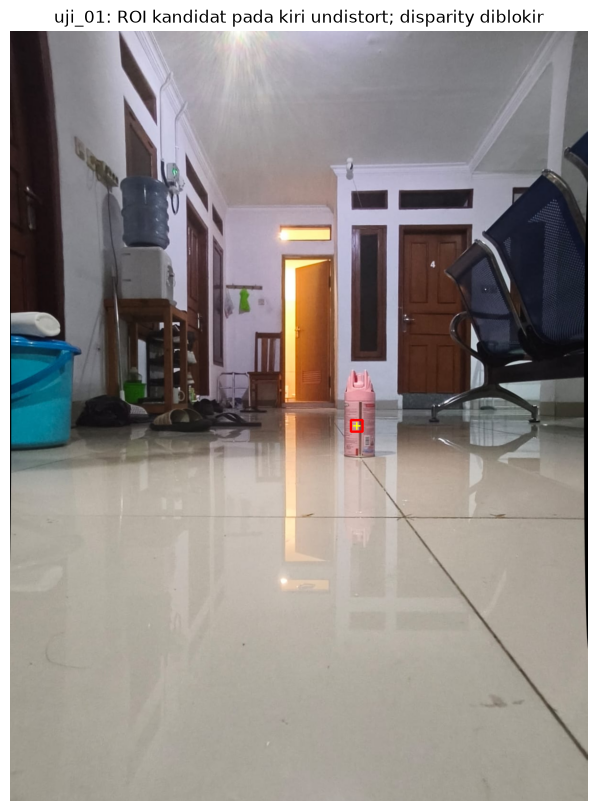

uji_2: ROI=(388, 838, 413, 863) | disparity valid=624/625 (99.8%) | disparity median bertanda=-425.00 px | depth=0.671 m | meteran=0.500 m | error=34.25%


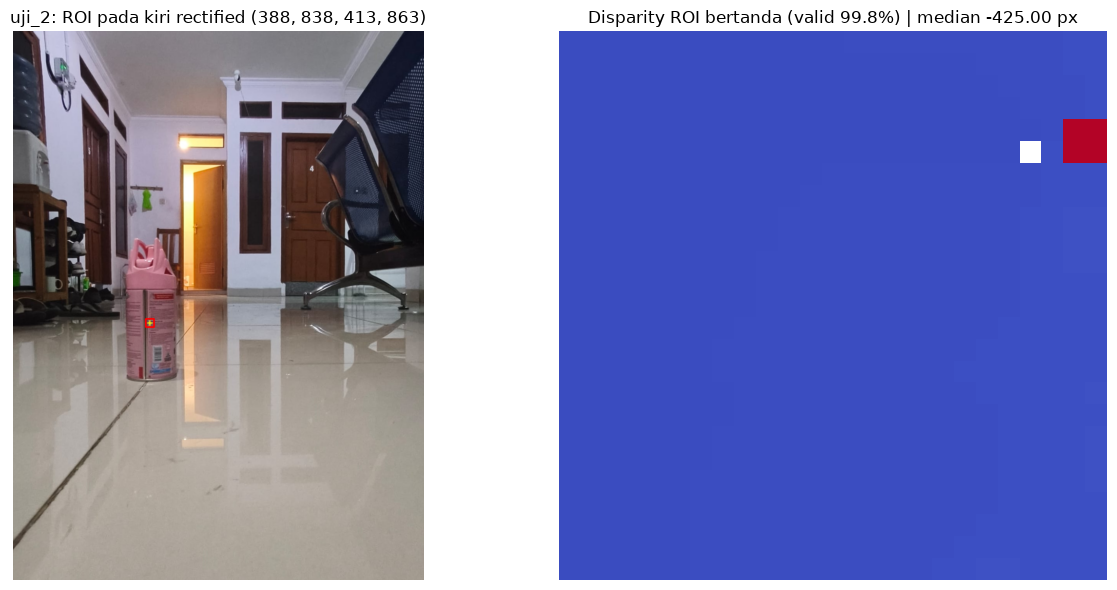

uji_3: ROI=(678, 828, 703, 853) | disparity valid=529/625 (84.6%) | disparity median bertanda=190.00 px | depth=1.403 m | meteran=1.500 m | error=6.45%


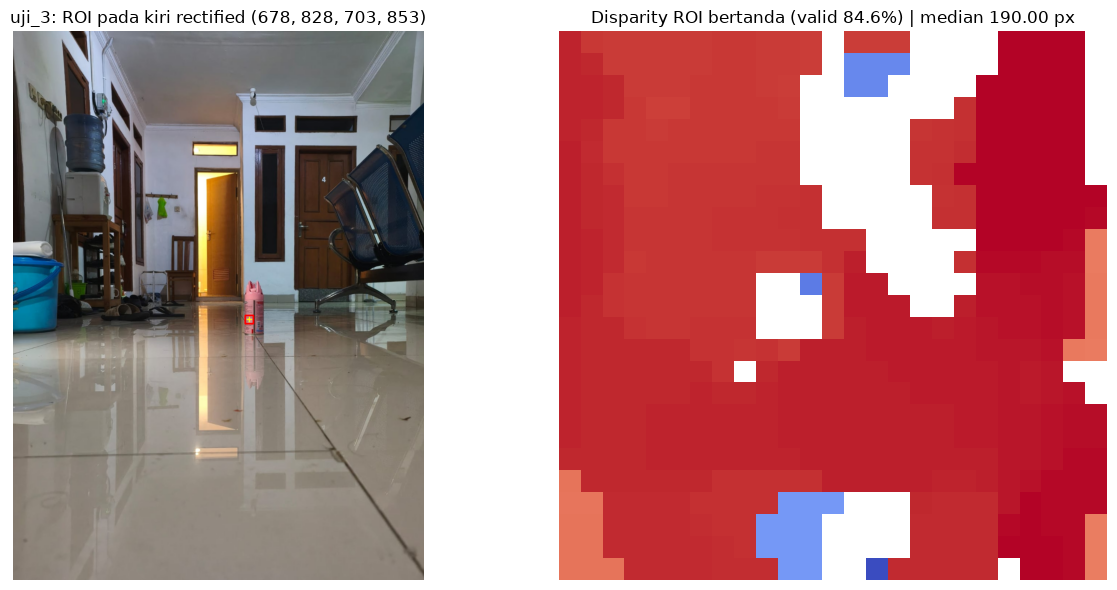

In [65]:
ROI_CONFIG={
    'uji_01':{'distance_cm':100,'center_xy':(720,820),'radius':12},
    'uji_2':{'distance_cm':50,'center_xy':(400,850),'radius':12},
    'uji_3':{'distance_cm':150,'center_xy':(690,840),'radius':12}}
trial_results={}
trial_errors={}
for test_id,config in ROI_CONFIG.items():
    try:
        result=run_stereo_trial(
            test_id,config['distance_cm'],config['center_xy'],config['radius'])
    except (RuntimeError,FileNotFoundError,ValueError,OSError) as exc:
        trial_errors[test_id]=str(exc)
        print(f'{test_id}: GAGAL ? {exc}')
        if test_id=='uji_01':
            source_left=cv2.imread(str(STEREO_DIR/'kiri 100.jpeg'))
            if source_left is not None:
                calibration=np.load(OUT/'calibration.npz')
                K_preview,dist_preview=portrait_camera_model(calibration,source_left.shape)
                undistorted_preview=cv2.undistort(
                    source_left,K_preview,dist_preview,None,K_preview)
                roi_x,roi_y=config['center_xy'];radius=config['radius']
                cv2.rectangle(
                    undistorted_preview,(roi_x-radius,roi_y-radius),
                    (roi_x+radius,roi_y+radius),(0,0,255),3)
                cv2.drawMarker(
                    undistorted_preview,(roi_x,roi_y),(0,255,255),
                    cv2.MARKER_CROSS,15,2)
                candidate_path=OUT/'roi_uji_01_candidate.jpg'
                if not cv2.imwrite(str(candidate_path),undistorted_preview):
                    raise OSError('Gagal menyimpan pratinjau ROI kandidat uji_01.')
                plt.figure(figsize=(8,10))
                plt.imshow(cv2.cvtColor(undistorted_preview,cv2.COLOR_BGR2RGB))
                plt.title('uji_01: ROI kandidat pada kiri undistort; disparity diblokir')
                plt.axis('off');plt.show()
        continue
    trial_results[test_id]=result
    record=result['record']
    print(
        f"{test_id}: ROI={result['roi_box']} | disparity valid="
        f"{result['valid_count']}/{result['valid_total']} "
        f"({result['valid_percent']:.1f}%) | disparity median bertanda="
        f"{record['disparity_roi_px']:.2f} px | depth="
        f"{record['depth_est_m']:.3f} m | meteran="
        f"{record['depth_meter_m']:.3f} m | error={record['error_pct']:.2f}%")
    fig,axes=plt.subplots(1,2,figsize=(13,6))
    axes[0].imshow(cv2.cvtColor(result['roi_preview'],cv2.COLOR_BGR2RGB))
    axes[0].set_title(f"{test_id}: ROI pada kiri rectified {result['roi_box']}")
    axes[0].axis('off')
    axes[1].imshow(np.ma.masked_invalid(result['roi_disparity']),cmap='coolwarm')
    axes[1].set_title(
        f"Disparity ROI bertanda (valid {result['valid_percent']:.1f}%) | "
        f"median {record['disparity_roi_px']:.2f} px")
    axes[1].axis('off')
    plt.tight_layout();plt.show()


## G ? Simpan hasil setelah inspeksi ketiga ROI
Jalankan hanya setelah uji 1, 2, dan 3 memiliki disparity valid serta kotak ROI telah diperiksa. Jika ada pasangan tidak valid, CSV tidak diperbarui.


In [66]:
required_trials={'uji_01','uji_2','uji_3'}
if BASELINE_CM<=0:
    raise ValueError('BASELINE_CM harus berisi baseline terukur positif.')
if not required_trials.issubset(trial_results):
    missing=sorted(required_trials-set(trial_results))
    raise RuntimeError(f'CSV tidak ditulis; hasil valid belum tersedia untuk: {missing}.')
csv_path=OUT/'hasil_pengukuran.csv'
new_records=[trial_results[test_id]['record'] for test_id in ('uji_01','uji_2','uji_3')]
fieldnames=list(new_records[0])
rows=[]
if csv_path.exists():
    with csv_path.open(encoding='utf-8',newline='') as fh:
        rows=list(csv.DictReader(fh))
rows=[row for row in rows if row.get('uji') not in {'uji_2','uji_3'}]
rows.extend(new_records)
with csv_path.open('w',encoding='utf-8',newline='') as fh:
    writer=csv.DictWriter(fh,fieldnames=fieldnames)
    writer.writeheader();writer.writerows(rows)
print('Tersimpan:',csv_path)
for record in new_records:
    print(
        f"{record['uji']} | disparity ROI {record['disparity_roi_px']} px | "
        f"estimasi {record['depth_est_m']} m | meteran {record['depth_meter_m']} m | "
        f"error {record['error_pct']}%")


RuntimeError: CSV tidak ditulis; hasil valid belum tersedia untuk: ['uji_01'].

## Tugas analisis dan flowchart
**Ikuti format pengumpulan di README bagian 8.** Buat sendiri dua flowchart: (1) **A→B→C** dengan keputusan berhasil/gagal mendeteksi sudut; (2) **D→E→F→G** dengan keputusan alignment/ROI valid. Bandingkan minimal tiga jarak dan tulis penyebab error.

**Batasan:** proses ini menggunakan pendekatan translasi horizontal murni. Pemeriksaan alignment saja **tidak membuktikan** seluruh asumsi geometri terpenuhi; jangan melaporkan hasil sebagai jarak metrik terverifikasi tanpa perbandingan meteran.